[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


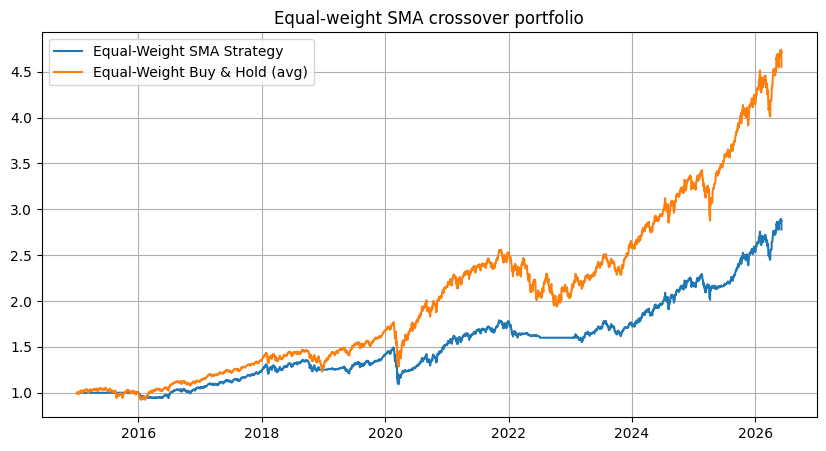

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Assets
tickers = ["SPY", "QQQ", "IWM", "GLD"]
n_assets = len(tickers)

# Download data
data = {}
for t in tickers:
    df = yf.download(t, start="2015-01-01", auto_adjust=True)
    data[t] = df[["Close"]].rename(columns={"Close": t})

# Combine into single DataFrame
prices = pd.concat(data.values(), axis=1)
prices = prices.dropna()

# Compute returns
returns = prices.pct_change().fillna(0)

# Compute signals (50/200 SMA crossover)
signals = pd.DataFrame(index=prices.index)

for t in tickers:
    ma50 = prices[t].rolling(50).mean()
    ma200 = prices[t].rolling(200).mean()

    signals[t] = (ma50 > ma200).astype(int)

signals = signals.shift(1).fillna(0)  # avoid look-ahead bias

# Equal-weight allocation among active signals
weights = signals / n_assets

# Handle days with no signals (all zeros)
weights = weights.fillna(0)

# Portfolio returns
strategy_returns = (weights * returns.values).sum(axis=1)

# Equity curves
equity = (1 + strategy_returns).cumprod()
buy_hold = (1 + returns.mean(axis=1)).cumprod()  # naive benchmark

# Plot
plt.figure(figsize=(10,5))
plt.plot(equity, label="Equal-Weight SMA Strategy")
plt.plot(buy_hold, label="Equal-Weight Buy & Hold (avg)")
plt.title("Equal-weight SMA crossover portfolio")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np

# Drop NaNs
strategy_returns = strategy_returns.dropna()
benchmark_returns = returns.mean(axis=1).dropna()

# Annualized Sharpe ratio (risk-free = 0)
strategy_sharpe = (
    strategy_returns.mean()
    / strategy_returns.std()
    * np.sqrt(252)
)

benchmark_sharpe = (
    benchmark_returns.mean()
    / benchmark_returns.std()
    * np.sqrt(252)
)

print(f"Equal-weight SMA Strategy Sharpe: {strategy_sharpe:.2f}")
print(f"Equal-weight Buy & Hold Sharpe:   {benchmark_sharpe:.2f}")

Equal-weight SMA Strategy Sharpe: 0.81
Equal-weight Buy & Hold Sharpe:   0.94
